In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")

print("Dataset loaded successfully")
print("Dataset shape:",df.shape)
display(df.head())



Dataset loaded successfully
Dataset shape: (80000, 18)


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
0,PROP-005003,Chandigarh,Mid-Range,Builder Floor,4,5,1293.82,862.81,21,36,11,Semi-Furnished,1,1,1,5.34,10.84,127.38
1,PROP-009920,Kolkata,Premium,Builder Floor,2,2,2438.03,1977.23,16,31,16,Semi-Furnished,1,1,1,3.48,8.69,214.61
2,PROP-003987,Delhi,Mid-Range,Villa,3,4,1065.54,721.68,2,3,32,Semi-Furnished,0,0,1,2.66,5.73,162.56
3,PROP-084186,Chandigarh,Mid-Range,Apartment,1,2,1611.76,1327.15,38,41,27,Semi-Furnished,1,1,0,1.33,10.70,124.88
4,PROP-068764,Ahmedabad,Premium,Independent House,5,5,1043.93,781.81,21,30,23,Unfurnished,0,1,0,1.75,7.22,94.77


In [4]:
# Remove extra spaces and special characters from column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(r"[^A-Za-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Clean column names:")
print(df.columns.tolist())

Clean column names:
['Property_ID', 'City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km', 'Price_INR_Lakhs']


In [5]:
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing numerical values with median
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
categorical_cols = df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    if df[col].isnull().any() and not df[col].mode().empty:
        df[col] = df[col].fillna(df[col].mode()[0])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Property_ID                   0
City                          0
Locality_Type                 0
Property_Type                 0
BHK                           0
Bathrooms                     0
Super_Area_SqFt               0
Carpet_Area_SqFt              0
Floor_Number                  0
Total_Floors                  0
Age_of_Property               0
Furnishing_Status             0
Parking                       0
Lift_Available                0
Gated_Community               0
Distance_to_Metro_km          0
Distance_to_City_Center_km    0
Price_INR_Lakhs               0
dtype: int64

Missing values after cleaning:
Property_ID                   0
City                          0
Locality_Type                 0
Property_Type                 0
BHK                           0
Bathrooms                     0
Super_Area_SqFt               0
Carpet_Area_SqFt              0
Floor_Number                  0
Total_Floors                  0
Age_of_Property            

In [6]:
print("Duplicate rows before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)

Duplicate rows before cleaning: 0
Duplicate rows after cleaning: 0
Updated dataset shape: (80000, 18)


In [7]:
print("Available columns:")
print(df.columns.tolist())

Available columns:
['Property_ID', 'City', 'Locality_Type', 'Property_Type', 'BHK', 'Bathrooms', 'Super_Area_SqFt', 'Carpet_Area_SqFt', 'Floor_Number', 'Total_Floors', 'Age_of_Property', 'Furnishing_Status', 'Parking', 'Lift_Available', 'Gated_Community', 'Distance_to_Metro_km', 'Distance_to_City_Center_km', 'Price_INR_Lakhs']


In [8]:
mumbai_properties = df[df["City"] == "Mumbai"]

print("Properties in Mumbai:", mumbai_properties.shape[0])
display(mumbai_properties.head())

Properties in Mumbai: 8024


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
13,PROP-004074,Mumbai,Mid-Range,Villa,3,4,1500.97,1266.93,10,31,10,Unfurnished,1,1,1,0.27,5.14,355.66
18,PROP-033742,Mumbai,Mid-Range,Independent House,4,4,1874.83,1517.72,19,33,11,Unfurnished,1,1,0,4.27,15.30,411.15
40,PROP-031231,Mumbai,Mid-Range,Apartment,6,6,1254.42,991.18,10,11,28,Furnished,1,1,0,5.27,1.06,228.84
44,PROP-052231,Mumbai,Mid-Range,Independent House,2,3,1443.11,973.99,5,9,6,Furnished,0,1,0,1.90,3.83,399.98
48,PROP-003054,Mumbai,Mid-Range,Builder Floor,2,2,1609.40,1235.00,2,15,2,Furnished,1,1,0,5.78,7.75,303.82


In [9]:
print("Available property types:")
print(df["Property_Type"].value_counts())

selected_properties = df[
    df["Property_Type"] == "Apartment"
]

display(selected_properties.head())

Available property types:
Property_Type
Apartment            20049
Villa                20031
Builder Floor        20022
Independent House    19898
Name: count, dtype: int64


,Property_ID,City,Locality_Type,Property_Type,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Furnishing_Status,Parking,Lift_Available,Gated_Community,Distance_to_Metro_km,Distance_to_City_Center_km,Price_INR_Lakhs
3,PROP-084186,Chandigarh,Mid-Range,Apartment,1,2,1611.76,1327.15,38,41,27,Semi-Furnished,1,1,0,1.33,10.70,124.88
5,PROP-081578,Pune,Premium,Apartment,3,3,1404.56,923.70,25,29,14,Unfurnished,1,1,1,0.19,10.39,215.52
7,PROP-020655,Ahmedabad,Affordable,Apartment,3,3,802.98,524.08,27,29,13,Furnished,1,1,0,3.48,11.55,29.45
8,PROP-074261,Ahmedabad,Mid-Range,Apartment,2,3,1093.82,887.41,16,31,23,Semi-Furnished,1,1,0,3.55,5.18,72.16
10,PROP-088327,Hyderabad,Mid-Range,Apartment,3,3,961.92,632.10,23,29,6,Unfurnished,1,1,1,2.65,4.62,111.89


In [10]:
categorical_cols = df.select_dtypes(
    include=["object"]
).columns.tolist()

# Exclude unique property identifier
categorical_cols = [
    col for col in categorical_cols
    if col != "Property_ID"
]

encoded_df = pd.get_dummies(
    df,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("Dataset after encoding:")
display(encoded_df.head())

print("Encoded dataset shape:", encoded_df.shape)

Dataset after encoding:


,Property_ID,BHK,Bathrooms,Super_Area_SqFt,Carpet_Area_SqFt,Floor_Number,Total_Floors,Age_of_Property,Parking,Lift_Available,...,City_Kolkata,City_Mumbai,City_Pune,Locality_Type_Mid-Range,Locality_Type_Premium,Property_Type_Builder Floor,Property_Type_Independent House,Property_Type_Villa,Furnishing_Status_Semi-Furnished,Furnishing_Status_Unfurnished
0,PROP-005003,4,5,1293.82,862.81,21,36,11,1,1,...,0,0,0,1,0,1,0,0,1,0
1,PROP-009920,2,2,2438.03,1977.23,16,31,16,1,1,...,1,0,0,0,1,1,0,0,1,0
2,PROP-003987,3,4,1065.54,721.68,2,3,32,0,0,...,0,0,0,1,0,0,0,1,1,0
3,PROP-084186,1,2,1611.76,1327.15,38,41,27,1,1,...,0,0,0,1,0,0,0,0,1,0
4,PROP-068764,5,5,1043.93,781.81,21,30,23,0,1,...,0,0,0,0,1,0,1,0,0,1


Encoded dataset shape: (80000, 30)


In [11]:
average_prices = df.groupby(
    ["City", "Property_Type"]
)["Price_INR_Lakhs"].mean().reset_index()

average_prices = average_prices.rename(
    columns={"Price_INR_Lakhs": "Average_Price_INR_Lakhs"}
)

display(average_prices.head(10))

,City,Property_Type,Average_Price_INR_Lakhs
0,Ahmedabad,Apartment,76.725656
1,Ahmedabad,Builder Floor,75.275108
2,Ahmedabad,Independent House,77.271130
3,Ahmedabad,Villa,75.301740
4,Bangalore,Apartment,153.046417
5,Bangalore,Builder Floor,148.633805
6,Bangalore,Independent House,151.911537
7,Bangalore,Villa,151.387165
8,Chandigarh,Apartment,128.341093
9,Chandigarh,Builder Floor,128.776015


In [12]:
city_summary = df.groupby("City")["Price_INR_Lakhs"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("City-wise price summary:")
display(city_summary)

City-wise price summary:


,count,mean,median,min,max
City,,,,,
Ahmedabad,7982,76.146560,56.730000,5.000000,1593.594285
Bangalore,8189,151.238115,113.970000,5.000000,1687.654876
Chandigarh,7873,126.942984,95.970000,5.000000,1902.470366
Chennai,8150,123.159102,92.820000,5.000000,1241.132514
Delhi,8037,226.998967,170.180000,5.000000,2066.850917
Hyderabad,8060,115.107165,85.795000,5.000000,2148.825381
Jaipur,8002,63.003885,46.475000,2.765306,1273.405455
Kolkata,7850,99.395469,74.705000,5.000000,1664.490058
Mumbai,8024,308.908895,232.542748,6.360000,3334.915208


In [13]:
outlier_cols = [
    "Super_Area_SqFt",
    "Carpet_Area_SqFt",
    "Distance_to_Metro_km",
    "Distance_to_City_Center_km",
    "Price_INR_Lakhs"
]

for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = (
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    )

    print(f"{col}: {outliers.sum()} outliers")

Super_Area_SqFt: 2503 outliers
Carpet_Area_SqFt: 2455 outliers
Distance_to_Metro_km: 331 outliers
Distance_to_City_Center_km: 289 outliers
Price_INR_Lakhs: 5355 outliers


In [14]:
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

print("Outlier handling completed!")

Outlier handling completed!


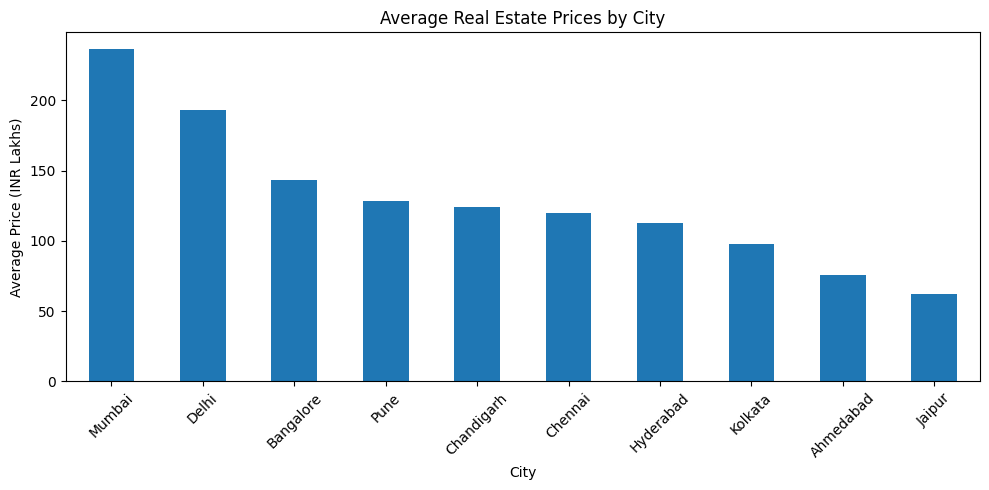

In [15]:
city_prices = df.groupby("City")[
    "Price_INR_Lakhs"
].mean().sort_values(ascending=False)

city_prices.plot(kind="bar", figsize=(10, 5))

plt.title("Average Real Estate Prices by City")
plt.xlabel("City")
plt.ylabel("Average Price (INR Lakhs)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
df.to_csv("RealEstate_Prices_Cleaned.csv", index=False)

encoded_df.to_csv(
    "RealEstate_Prices_Encoded.csv",
    index=False
)

average_prices.to_csv(
    "Average_Prices_by_City_and_Property_Type.csv",
    index=False
)

print("All output files saved successfully!")

All output files saved successfully!
